Top 10 Longest Tracks
                                     track_name                artist  duration_min
                                       Lost Boy                 Jaden      9.497883
                              I'm Getting Ready   Tasha Cobbs Leonard      8.436667
                                        Mirrors     Justin Timberlake      8.069100
What Goes Around.../...Comes Around (Interlude)     Justin Timberlake      7.476217
                             Achilles Come Down        Gang of Youths      7.035767
                           Never Let Go (Of Me)                Baltra      6.909833
          House Of Balloons / Glass Table Girls            The Weeknd      6.753550
                                           Stan                Eminem      6.735100
                                      Galvanize The Chemical Brothers      6.563550
                                    After Hours            The Weeknd      6.017100


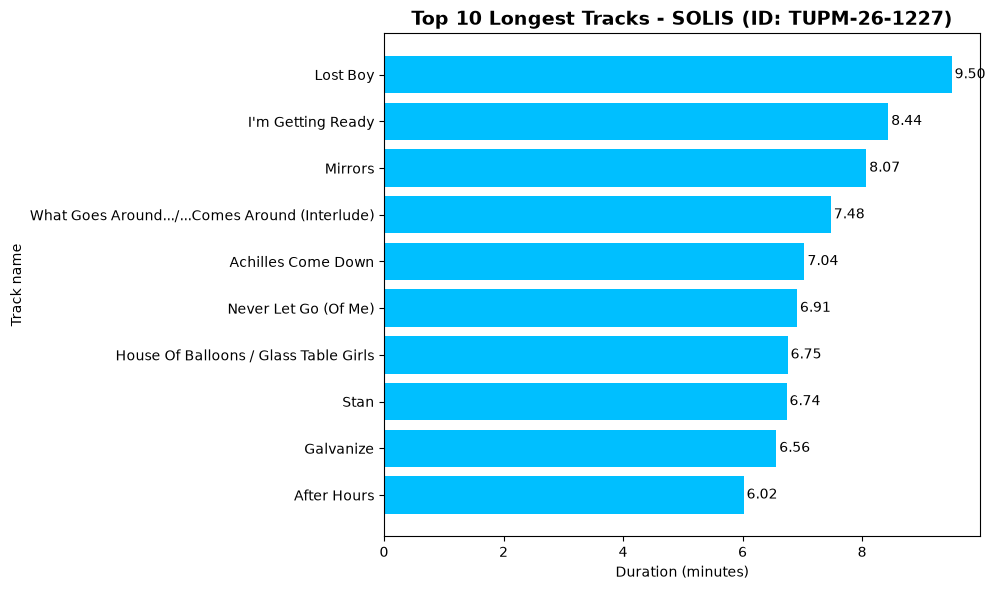

In [1]:
# Identify Longest Tracks

import pandas as pd
import matplotlib.pyplot as plt

# ---------- Student-specific parameters ----------
student_name = "SOLIS"
student_id = "TUPM-26-1227"
color_bar = "deepskyblue"          # any matplotlib color name or hex code

# ---------- Load data ----------
df = pd.read_csv(r"C:\Users\n0n3\Lab8_DataVisualization_Solis\data\spotify_top_1000_tracks.csv")   # change to your CSV filename
df = df[["track_name", "artist", "duration_min"]]

# ---------- Calculations ----------
top10 = (
    df.sort_values("duration_min", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

# ---------- Output 1: table ----------
print("Top 10 Longest Tracks")
print(top10.to_string(index=False))

# ---------- Output 2: horizontal bar chart ----------
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10["track_name"], top10["duration_min"], color=color_bar)

ax.invert_yaxis()   # longest track at the top
ax.set_xlabel("Duration (minutes)")
ax.set_ylabel("Track name")
ax.set_title(f"Top 10 Longest Tracks - {student_name} (ID: {student_id})",
            fontsize=14, fontweight="bold")

# label each bar with its duration
for i, v in enumerate(top10["duration_min"]):
    ax.text(v + 0.05, i, f"{v:.2f}", va="center")

plt.tight_layout()
plt.show()


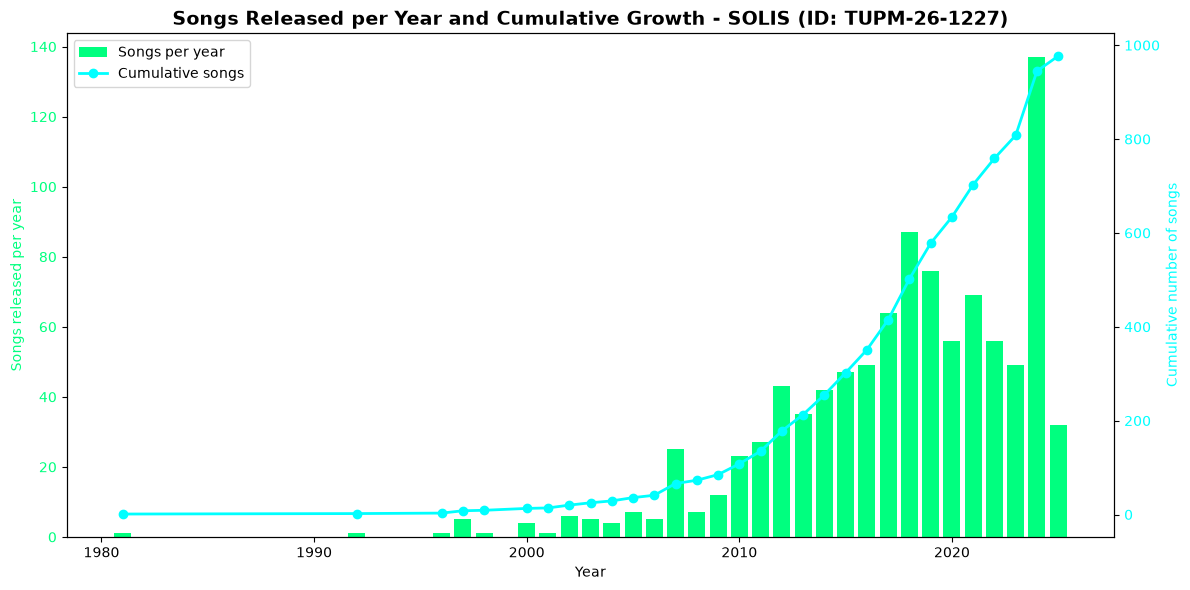

In [2]:
#  Song Release Trend

import pandas as pd
import matplotlib.pyplot as plt

# ---------- Student-specific parameters ----------
student_name = "SOLIS"
student_id = "TUPM-26-1227"
color_bar = "springgreen"
color_line = "aqua"

# ---------- Load data ----------
df = pd.read_csv(r"C:\Users\n0n3\Lab8_DataVisualization_Solis\data\spotify_top_1000_tracks.csv")   # change to your CSV path
df["year"] = pd.to_datetime(df["release_date"], errors="coerce").dt.year
df = df[["year"]].dropna()
df["year"] = df["year"].astype(int)

# ---------- Calculations ----------
yearly = df.groupby("year").size()
cumulative = yearly.cumsum()
# ---------- Combined bar + line chart ----------
fig, ax1 = plt.subplots(figsize=(12, 6))

# bars: yearly counts (left y-axis)
ax1.bar(yearly.index, yearly.values, color=color_bar, label="Songs per year")
ax1.set_xlabel("Year")
ax1.set_ylabel("Songs released per year", color=color_bar)
ax1.tick_params(axis="y", labelcolor=color_bar)

# line: cumulative count (right y-axis)
ax2 = ax1.twinx()
ax2.plot(cumulative.index, cumulative.values, color=color_line,
        marker="o", linewidth=2, label="Cumulative songs")
ax2.set_ylabel("Cumulative number of songs", color=color_line)
ax2.tick_params(axis="y", labelcolor=color_line)

# one combined legend
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")

ax1.set_title(f"Songs Released per Year and Cumulative Growth - "
            f"{student_name} (ID: {student_id})",
            fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

Saved hexbin_animation.gif


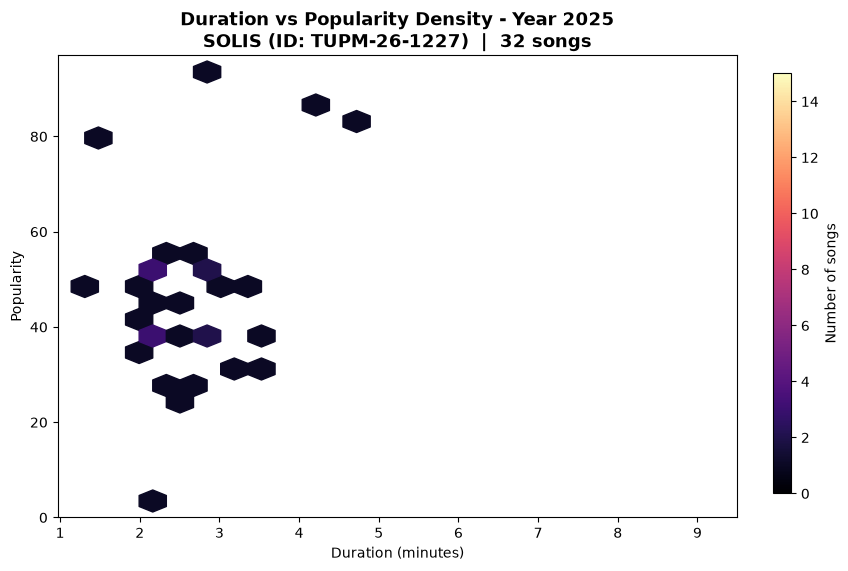

In [3]:
#Animated Density Map of Duration vs Popularity

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# ---------- Student-specific parameters ----------
student_name = "SOLIS"
student_id = "TUPM-26-1227"
cmap_color = "magma"      # any matplotlib colormap: "plasma", "magma", "Blues", ...

# ---------- Load data ----------
df = pd.read_csv(r"C:\Users\n0n3\Lab8_DataVisualization_Solis\data\spotify_top_1000_tracks.csv")   # change to your CSV path
df["year"] = pd.to_datetime(df["release_date"], errors="coerce").dt.year
df = df[["duration_min", "popularity", "year"]].dropna()
df["year"] = df["year"].astype(int)

# ---------- Calculations ----------
years = sorted(df["year"].unique())

# Fixed axis limits and grid so every frame is comparable
xmin, xmax = df["duration_min"].min(), df["duration_min"].max()
ymin, ymax = df["popularity"].min(), df["popularity"].max()
extent = (xmin, xmax, ymin, ymax)
gridsize = 25

# Fixed color scale: use the highest bin count found in any single year
vmax = 1
for y in years:
    sub = df[df["year"] == y]
    hb = plt.hexbin(sub["duration_min"], sub["popularity"],
                    gridsize=gridsize, extent=extent)
    vmax = max(vmax, hb.get_array().max())
plt.close()

# ---------- Animation ----------
fig, ax = plt.subplots(figsize=(9, 6))
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])   # fixed colorbar position
fig.subplots_adjust(right=0.88)

def update(frame):
    ax.clear()
    cax.clear()
    year = years[frame]
    sub = df[df["year"] == year]

    hb = ax.hexbin(sub["duration_min"], sub["popularity"],
                gridsize=gridsize, extent=extent,
                cmap=cmap_color, vmin=0, vmax=vmax, mincnt=1)
    fig.colorbar(hb, cax=cax, label="Number of songs")

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel("Duration (minutes)")
    ax.set_ylabel("Popularity")
    ax.set_title(f"Duration vs Popularity Density - Year {year}\n"
                f"{student_name} (ID: {student_id})  |  {len(sub)} songs",
                fontsize=13, fontweight="bold")

anim = FuncAnimation(fig, update, frames=len(years), interval=800, repeat=True)

# Save as GIF (works in both scripts and notebooks)
anim.save("hexbin_animation.gif", writer=PillowWriter(fps=1.2))
print("Saved hexbin_animation.gif")

plt.show()

# In a Jupyter notebook, use this instead of plt.show() to play it inline:
# from IPython.display import HTML
# HTML(anim.to_jshtml())